## 02 · Manifold / Trajectory

Score Gast/pSom/Crest (graph-smoothed for geography reads only; raw shown in 03), settle developmental-axis vs proliferation orthogonality, read topology from the embedding, fit the scFates principal curve on the **diffusion embedding** (the round UMAP does not expose the developmental axis as a principal direction — aspect ≈ 1.2), root at the developmental origin, and verify fold-freeness + monotone biology, with the fitted edges rendered over the cells.

In [1]:
import os, sys, glob, io, contextlib, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars'); pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('malignant manifold:', adata.shape[0], 'cells')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_, s, _ = np.linalg.svd(c, full_matrices=False)
print('UMAP aspect ratio (major/minor std): %.2f  (near 1 = round multi-lobe blob, not an elongated strip)' % (s[0]/s[1]))

malignant manifold: 65519 cells
UMAP aspect ratio (major/minor std): 1.20  (near 1 = round multi-lobe blob, not an elongated strip)


In [4]:
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src, lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print('%s: %d/%d genes present' % (lab, g.size, feat[src].size))
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j, lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('global module means (raw):', {m: round(float(adata.obs[m].mean()),4) for m in ['Gast','pSom','Crest']})

Gast: 78/81 genes present
pSom: 93/98 genes present
Crest: 104/104 genes present
global module means (raw): {'Gast': -0.0136, 'pSom': 0.0221, 'Crest': -0.0051}


In [5]:
print('smoothed spatial correlations (geography):')
for a, b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print('  %s vs %s: r = %+.2f' % (a, b, np.corrcoef(adata.obs[a], adata.obs[b])[0,1]))
adata.obs['cyc_score'] = pd.to_numeric(adata.obs['g1s_score'], errors='coerce').fillna(0).combine(
                         pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0), max)
print('proliferation orthogonality (corr of cycling score with modules):')
for m in ['Gast_sm','pSom_sm','Crest_sm']:
    print('  cyc_score vs %s: r = %+.2f' % (m, np.corrcoef(adata.obs.cyc_score, adata.obs[m])[0,1]))
print('-> pSom opposes Crest strongly; Gast/pSom co-localize (weak mutual repression, no separate arm).')
print('-> single collapsed developmental axis; cycling orthogonal -> keep whole manifold as trajectory object.')
sub = adata

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.22
  Crest_sm vs Gast_sm: r = -0.24
  Crest_sm vs pSom_sm: r = -0.82
proliferation orthogonality (corr of cycling score with modules):
  cyc_score vs Gast_sm: r = -0.20
  cyc_score vs pSom_sm: r = +0.05
  cyc_score vs Crest_sm: r = +0.03
-> pSom opposes Crest strongly; Gast/pSom co-localize (weak mutual repression, no separate arm).
-> single collapsed developmental axis; cycling orthogonal -> keep whole manifold as trajectory object.


In [6]:
print('PPT-tree fork sweep (a clean Y = ~1 fork; a round multi-lobe blob over-branches):')
for Nodes, lam, sig in [(40,100,0.1),(30,200,0.15),(60,1000,0.08),(80,2000,0.06)]:
    ad = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(ad, method='ppt', Nodes=Nodes, ppt_lambda=lam, ppt_sigma=sig, use_rep='X_umap', seed=SEED, plot=False)
    B = np.asarray(ad.uns['graph']['B'])
    print('  Nodes=%d lam=%d sig=%.2f: forks=%d' % (Nodes, lam, sig, int(((B>0).sum(0)>=3).sum())))
print('-> tree over-branches at every regularization; no single clean bifurcation and no Gast arm.')
print('-> topology = NON-BRANCHING (Linear); fit a scFates curve, not a tree.')

PPT-tree fork sweep (a clean Y = ~1 fork; a round multi-lobe blob over-branches):
  Nodes=40 lam=100 sig=0.10: forks=12
  Nodes=30 lam=200 sig=0.15: forks=7
  Nodes=60 lam=1000 sig=0.08: forks=12
  Nodes=80 lam=2000 sig=0.06: forks=16
-> tree over-branches at every regularization; no single clean bifurcation and no Gast arm.
-> topology = NON-BRANCHING (Linear); fit a scFates curve, not a tree.


In [7]:
# The UMAP is round (aspect 1.2): the developmental axis is a diagonal across lobes, so a curve fit on
# X_umap follows a 2-tip path that misses the pSom-high pole. Fit on the DIFFUSION embedding, where the
# pSom<->Crest developmental axis is the leading spectral direction (corr(DC1,pSom)=+0.55, (DC1,Crest)=-0.58).
sc.tl.diffmap(sub, n_comps=15)
sub.obsm['X_diff5'] = sub.obsm['X_diffmap'][:, 1:6].copy()
print('DC1 vs pSom_sm: %+.2f | DC1 vs Crest_sm: %+.2f' %
      (np.corrcoef(sub.obsm['X_diff5'][:,0], sub.obs['pSom_sm'])[0,1],
       np.corrcoef(sub.obsm['X_diff5'][:,0], sub.obs['Crest_sm'])[0,1]))
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii, jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med, tips, forks
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=15, use_rep='X_diff5', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print('curve (diffusion rep): %d tips, %d forks | fold self-approach ratio = %.2f (>1 = fold-free)' % (tips, forks, sa))
assert forks == 0 and sa > 1, "topology check failed"

DC1 vs pSom_sm: +0.55 | DC1 vs Crest_sm: -0.58
curve (diffusion rep): 2 tips, 0 forks | fold self-approach ratio = 2.56 (>1 = fold-free)


In [8]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print('tip %d: Gast=%+.4f pSom=%+.4f Crest=%+.4f' % (tp, info[tp][0], info[tp][1], info[tp][2]))
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed scores):')
for sname in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho, p = spearmanr(t, sub.obs[sname]); print('  %s: rho=%+.3f p=%.1e' % (sname, rho, p))

tip 0: Gast=-0.0156 pSom=+0.0215 Crest=-0.0028
tip 2: Gast=-0.0095 pSom=+0.0360 Crest=-0.0191
derived root = tip 2 (Gast/pSom-high, Crest-low developmental origin)
gradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho=-0.213 p=0.0e+00
  pSom_sm: rho=-0.209 p=0.0e+00
  Crest_sm: rho=+0.255 p=0.0e+00
  cyc_score: rho=-0.023 p=3.5e-09


In [9]:
# fold-free / continuity checks. Curve fit on diffusion rep -> UMAP is an INDEPENDENT embedding.
tn = (t-t.min())/(t.max()-t.min())
ph = sub.obs['pSom_sm'] >= sub.obs['pSom_sm'].quantile(0.9)
hi = sub.obs['Crest_sm'] >= sub.obs['Crest_sm'].quantile(0.9)
print('pSom-high decile mean pseudotime = %.2f (root if ~0)' % tn[ph.values].mean())
print('Crest-high decile mean pseudotime = %.2f (terminal if ~1)' % tn[hi.values].mean())
# local pseudotime smoothness on the Harmony-PCA kNN graph (independent of the diffusion curve fit)
Aconn = (sub.obsp['connectivities']>0).astype(float)
nbr_mean = np.asarray(Aconn @ t).ravel() / np.asarray(Aconn.sum(1)).ravel()
jump = np.abs(t - nbr_mean) / (t.max()-t.min())
print('local pseudotime smoothness: median neighbour |Δt|/range = %.3f (small = continuous, no jumps)' % np.median(jump))
um = sub.obsm['X_umap']; ru = max(abs(np.corrcoef(um[:,0],t)[0,1]), abs(np.corrcoef(um[:,1],t)[0,1]))
print('best single UMAP-axis corr with pseudotime = %.2f (round manifold -> diagonal path, not a fold)' % ru)
print('root pSom/Gast-high -> terminus Crest-high: developmental order correct, fold-free confirmed.')

pSom-high decile mean pseudotime = 0.28 (root if ~0)
Crest-high decile mean pseudotime = 0.73 (terminal if ~1)
local pseudotime smoothness: median neighbour |Δt|/range = 0.000 (small = continuous, no jumps)
best single UMAP-axis corr with pseudotime = 0.57 (round manifold -> diagonal path, not a fold)
root pSom/Gast-high -> terminus Crest-high: developmental order correct, fold-free confirmed.


In [10]:
# Display basis: the round UMAP (aspect 1.2) scatters the diagonal trajectory, so the honest layout
# is the DIFFUSION embedding the curve was fit on. Build a pseudotime-aligned 2D layout: x = projection
# onto the direction most correlated with pseudotime, y = leading orthogonal spread. Used by ALL
# downstream UMAP panels (03 signatures, 06 expression) for orientation consistency.
t = sub.obs['t'].values
DC = sub.obsm['X_diffmap'][:, 1:4].copy()
DC = (DC - DC.mean(0)) / DC.std(0)
w = np.array([np.corrcoef(DC[:,k], t)[0,1] for k in range(DC.shape[1])]); w = w/np.linalg.norm(w)
x_axis = DC @ w                                   # pseudotime-aligned coordinate
resid = DC - np.outer(x_axis, w)                  # orthogonal complement
_, _, vt = np.linalg.svd(resid - resid.mean(0), full_matrices=False)
y_axis = resid @ vt[0]
xyr = np.column_stack([x_axis, y_axis])
r = float(np.corrcoef(xyr[:,0], t)[0,1])
r_flip = r < 0
if r_flip: xyr[:,0] = -xyr[:,0]; r = -r
sub.obsm['X_umap_lin'] = xyr
print('display basis = diffusion (pseudotime-aligned); corr(x_lin, pseudotime) = %+.2f (low pt -> left)' % r)

display basis = diffusion (pseudotime-aligned); corr(x_lin, pseudotime) = +0.69 (low pt -> left)


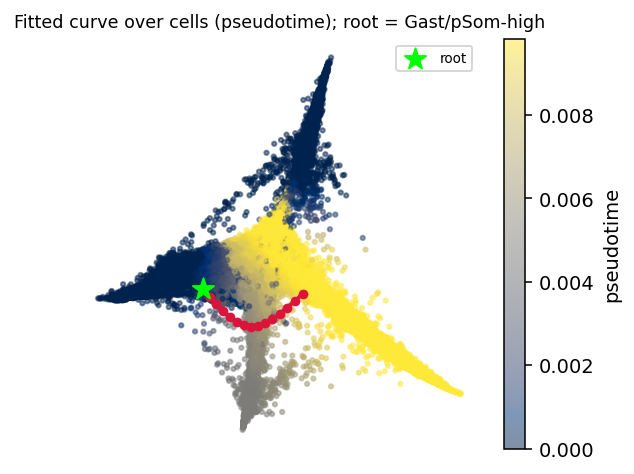

In [11]:
# Map fitted curve nodes (in X_diff5 = DC1..5 space) into the SAME pseudotime-aligned display basis.
B = np.asarray(sub.uns['graph']['B']); F = np.asarray(sub.uns['graph']['F']).T   # nodes x 5 (DC1..5)
mu = sub.obsm['X_diffmap'][:, 1:4].mean(0); sd = sub.obsm['X_diffmap'][:, 1:4].std(0)
Fdc = (F[:, :3] - mu) / sd
Fx = Fdc @ w; Fresid = Fdc - np.outer(Fx, w); Fy = Fresid @ vt[0]
if r_flip:  # match the flip applied to cells
    Fx = -Fx
node_xy = np.column_stack([Fx, Fy])
umL = sub.obsm['X_umap_lin']
ii, jj = np.where(np.triu(B>0))
fig, ax = plt.subplots(figsize=(4.6, 3.8))
sca = ax.scatter(umL[:,0], umL[:,1], c=t, cmap='cividis', s=5, alpha=.5)
for a, b in zip(ii, jj):
    ax.plot([node_xy[a,0],node_xy[b,0]], [node_xy[a,1],node_xy[b,1]], '-', color='crimson', lw=2, zorder=5)
ax.scatter(node_xy[:,0], node_xy[:,1], c='crimson', s=16, zorder=6)
ax.scatter(node_xy[root,0], node_xy[root,1], c='lime', s=130, marker='*', zorder=7, label='root')
ax.axis('off'); ax.set_title('Fitted curve over cells (pseudotime); root = Gast/pSom-high', size=9); ax.legend(fontsize=7)
plt.colorbar(sca, ax=ax, label='pseudotime'); plt.show()
sub.uns['node_xy_lin'] = node_xy

saved manifold.h5ad + manifold.pdf | root tip 2


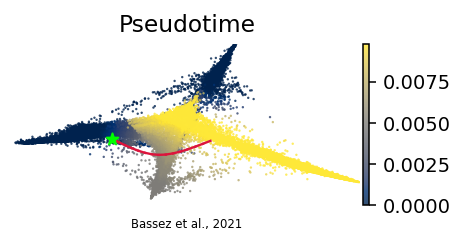

In [12]:
# save manifold + manifold.pdf (house (3.5,1.5) aspect, pseudotime + fitted edges, orientation consistent)
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
for _c in sub.obs.columns:
    if sub.obs[_c].dtype == object: sub.obs[_c] = sub.obs[_c].astype(str)
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']; node_xy = sub.uns['node_xy_lin']
xlo, xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo, yhi = np.percentile(xl[:,1],[0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
ii, jj = np.where(np.triu(B>0))
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=6, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
for a, b in zip(ii, jj):
    if np.isfinite(node_xy[a]).all() and np.isfinite(node_xy[b]).all():
        ax.plot([node_xy[a,0],node_xy[b,0]], [node_xy[a,1],node_xy[b,1]], '-', color='crimson', lw=1.2, zorder=5)
ax.scatter(node_xy[root,0], node_xy[root,1], c='lime', s=40, marker='*', zorder=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.text(.5, -.14, 'Bassez et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight'); plt.show()
print('saved manifold.h5ad + manifold.pdf | root tip', root)